In [11]:
import joblib
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

In [12]:
data = joblib.load("../src/split.joblib")
x_train = data["x_train"]
y_train = data["y_train"]
x_test = data["x_test"]
y_test = data["y_test"]
x_val = data["x_val"]
y_val = data["y_val"]

In [ ]:
# Redimensionner et normaliser les images.
BATCH_SIZE = 32
IMG_SIZE = (224 , 224)
IMG_SHAPE = (224 , 224 , 3)

preprocessing = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomRotation(0.1)
])

def load_image(image_path):
    image_path = image_path.decode("utf-8")
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE)
    # image = image.astype("float32") / 255.0
    image = image.astype("float32")
    # mobilenet expect [-1 , 1] scale
    return image

def load_preprocess_img(image_path , label , train = False) :
    img = tf.numpy_function(load_image , [image_path] , tf.float32)
    img.set_shape(IMG_SHAPE)
    if train : 
        img = preprocessing(img , training=True)
    return img , label

def create_dataset(image_paths , label , training = False) :
    dataset = tf.data.Dataset.from_tensor_slices((image_paths , label))
    if training : 
        dataset = dataset.shuffle(buffer_size=len(image_paths) , seed = 100)
    dataset = dataset.map(lambda image_path , label : load_preprocess_img(image_path , label , training) , num_parallel_calls=tf.data.AUTOTUNE )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

In [29]:
dts_train = create_dataset(x_train , y_train , training = True)
dts_test = create_dataset(x_test , y_test)
dts_val = create_dataset(x_val , y_val)

In [30]:
for name , data in [('train' ,dts_train) , ('test' ,dts_test ) , ('val' ,dts_val )] :
    print(f"{name}".center(40 , "-"))
    for images, labels in data.take(1):
        print("Images shape:", images.shape)
        print("Labels shape:", labels.shape)
        print("Labels:", labels.numpy())
        print("Min pixel:", tf.reduce_min(images).numpy())
        print("Max pixel:", tf.reduce_max(images).numpy())

from collections import Counter
val = [label for _ , labels in dts_val for label in labels.numpy()]
print(Counter(val))

-----------------train------------------
Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Labels: [1 2 1 3 0 3 3 3 0 1 3 3 0 2 3 0 1 1 2 2 0 1 2 1 3 3 0 1 3 1 3 0]
Min pixel: 0.0
Max pixel: 255.0
------------------test------------------
Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Labels: [1 1 1 0 2 3 1 1 3 0 3 2 1 1 3 3 0 3 3 2 0 2 2 1 3 1 0 2 1 1 0 2]
Min pixel: 0.0
Max pixel: 255.0
------------------val-------------------
Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Min pixel: 0.0
Max pixel: 254.0
Counter({np.int32(1): 140, np.int32(0): 136, np.int32(3): 136, np.int32(2): 100})


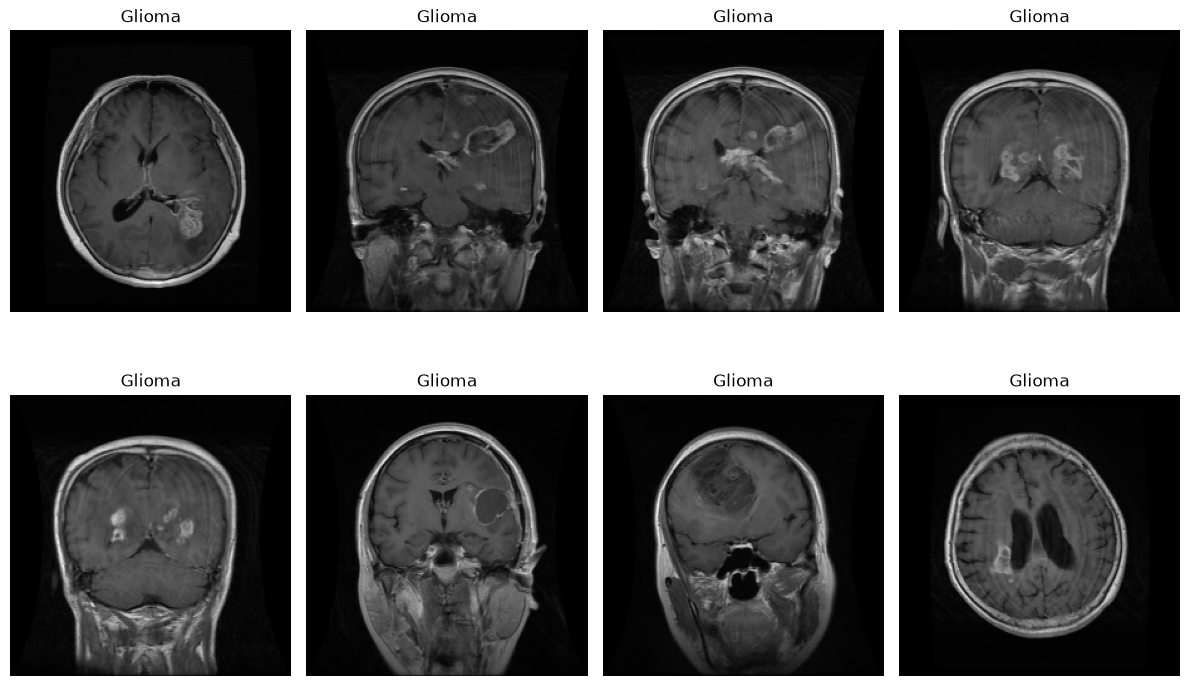

In [37]:
class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}
img , label = next(iter(dts_train))
plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

                

In [38]:
dts_train.save('../data/dts_train')
dts_test.save('../data/dts_test')
dts_val.save('../data/dts_val')